<a href="https://colab.research.google.com/github/cduffy57/Github-and-Jupyter-setup/blob/main/penguins_supervised_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## The Palmer Penguins  
<img src="https://allisonhorst.github.io/palmerpenguins/reference/figures/lter_penguins.png" alt="Palmer Penguins" style="width:500px;"/>

The Palmer Penguins dataset was first created by Allison Horst, Alison Hill, and Kristen Gorman and was made publicly available as an R package. The dataset includes 344 observations of Adélie, Chinstrap, and Gentoo penguins observed on islands in Antarctica. We are going to use the Palmer Penguins dataset for exercises in linear and logistic regression.

In [123]:
# loading the first of a few modules we'll use.
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [124]:
# laod the penguin data from the following URL (it's a CSV file)
pd_URL = "https://raw.githubusercontent.com/mcnakhaee/palmerpenguins/refs/heads/master/palmerpenguins/data/penguins.csv"
penguin_data =  pd.read_csv(pd_URL)## read the data here

# then take a look at the head or tail
penguin_data.head()


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


### Missing data: Seek and destroy!
**Seek**: Make sure there are no `NaN`, missing, values in the data. You might remember a couple ways to do this first look.  

**Destroy**: You have to decide what step to take next. That decision will depend on a few things, one of which might be how many missing values exist. If the numbers aren't huge, it may be easiest just to delete the rows that contain them. You could also replace them with mean or other values.   

Your choice on this one. Write your code below and include comments that explain what you're doing and why you made your decision(s).

In [125]:
# Look for missing values in this cell
penguin_data.isna().sum()


,0
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11
year,0


In [126]:
# Eliminate the missing values in this cell. Leave comments explaining your elimination strategy.

#with only 11 penguins having missing data, it was worth it to eliminate them from the sample.
#there was some thought given to keeping the sex of the penguins and dropping only the 2 with no data, but 9 penguins in a sample size of 343 seemed insignificant

penguin_data = penguin_data.dropna()

In [127]:
# check to see there are no missing values with info()
penguin_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 333 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            333 non-null    object 
 1   island             333 non-null    object 
 2   bill_length_mm     333 non-null    float64
 3   bill_depth_mm      333 non-null    float64
 4   flipper_length_mm  333 non-null    float64
 5   body_mass_g        333 non-null    float64
 6   sex                333 non-null    object 
 7   year               333 non-null    int64  
dtypes: float64(4), int64(1), object(3)
memory usage: 23.4+ KB


### How many of each species?

Let's take a look at how many penguins are in each species.

In [128]:
# How can we find the number of penguins in each of the three species? Remember value_counts()?
penguin_data['species'].value_counts()

,count
species,
Adelie,146
Gentoo,119
Chinstrap,68


### Getting the numeric columns
You'll see that some of the columns are numerical, others aren't. The numeric ones look interesting since they contain physical mesurements of each penguin (e.g., `bill_depth_mm`).

Make a list called `numeric_columns` that holds the names of the numeric columns.

In [129]:
# make a list called `numeric_columns` that holds the names of the numeric columns.
numeric_columns = ['bill_length_mm','bill_depth_mm', 'flipper_length_mm', 'body_mass_g']  # replace with your code


# make a copy of data with just numerical_columns
penguin_numeric_only = penguin_data[numeric_columns]

### Exploring the numerical values
First, call `.describe()` on penguin_data to see some summary statistics.

In [130]:
# what does .describe() tell us?
penguin_numeric_only.describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,333.000000,333.000000,333.000000,333.000000
mean,43.992793,17.164865,200.966967,4207.057057
std,5.468668,1.969235,14.015765,805.215802
min,32.100000,13.100000,172.000000,2700.000000
25%,39.500000,15.600000,190.000000,3550.000000
50%,44.500000,17.300000,197.000000,4050.000000
75%,48.600000,18.700000,213.000000,4775.000000
max,59.600000,21.500000,231.000000,6300.000000


This is useful to see the overall mean, minimum value, maximum values, etc. for the *entire* dataset.
What if we want to look at the `mean`, `std`, `min`, and `max`? We can tell `.describe()` to only display those values by adding `.loc[[value1, value2,...valueN]]` to the `.describe()` call. Here's how it looks.



In [131]:
# use .loc[] to select just the mean, std, min, and max in describe
penguin_data.describe().loc[['mean', 'std', 'min', 'max']]

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
mean,43.992793,17.164865,200.966967,4207.057057,2008.042042
std,5.468668,1.969235,14.015765,805.215802,0.812944
min,32.100000,13.100000,172.000000,2700.000000,2007.000000
max,59.600000,21.500000,231.000000,6300.000000,2009.000000


That worked. But why does it work? When you call `.describe()`, it returns a DataFrame. Let's make sure that's true.

In [132]:
# what does .describe() return?
describe_returns = penguin_data.describe()
print(".describe returns a", type(describe_returns))

.describe returns a <class 'pandas.core.frame.DataFrame'>


`.describe()` takes a DataFrame and produces a new DataFrame with summary stats. That means we can manipulate just like we'd do with any other data table!

`.loc[]` allows you to select rows from a DataFrame. Here's the function call from above.

```
penguin_data.describe().loc[['mean', 'std', 'min', 'max']]
```  

This uses `.loc[]` to extract the rows named 'mean', 'std', 'min', and 'max'. We have to include these in a list (['mean', 'std', 'min', 'max']) to tell `.loc` to choose multiple rows. You can use `.loc` to choose rows much as you've used `df['column_name]` to select different columns.




Now let's look at those same values (`mean`, `std`, `min`, and `max`) for *each species* of penguin. That is, the numbers above show summary statistics for the entire dataset. Can we get the same information for each penguin species?

Remember `groupby()` from the last module? We can take the penguin data and group it by species. We could use `.describe()`, but we're going to use a different technique that's much cleaner for grouped data. In particular, we group by species, and then specify the columns we want to describe. We defined a variable earlier, `numeric_columns`, that holds names those columns. Then we use the `.agg()`, or aggregate, function to do the desired statistical calculations.

In [133]:
# Group by species and then specify the numberic columns. Use .agg with a list of stats you want to
# compute and display. Finally, use .T to transpose the table...much more readable that way. And
# why not round the results to 2 decimal points.
penguin_data.groupby('species')[numeric_columns].agg(['mean', 'std',
'min', 'max']).T.round(2)

species                  Adelie  Chinstrap   Gentoo
bill_length_mm    mean    38.82      48.83    47.57
                  std      2.66       3.34     3.11
                  min     32.10      40.90    40.90
                  max     46.00      58.00    59.60
bill_depth_mm     mean    18.35      18.42    15.00
                  std      1.22       1.14     0.99
                  min     15.50      16.40    13.10
                  max     21.50      20.80    17.30
flipper_length_mm mean   190.10     195.82   217.24
                  std      6.52       7.13     6.59
                  min    172.00     178.00   203.00
                  max    210.00     212.00   231.00
body_mass_g       mean  3706.16    3733.09  5092.44
                  std    458.62     384.34   501.48
                  min   2850.00    2700.00  3950.00
                  max   4775.00    4800.00  6300.00

Much like the results of `.describe()`, we can see summary statistics for the numerical data. But we see these aggregated for each species. So it's easy to compare the mean `bill_length` for the three species. You should see that Chinstrap has the greatest mean for that variable, and it's pretty close to the mean for Gentoo. There are other similarities and differences you can spot by looking at the data this way.


Correlation maps are another useful way to see potential relationships between variables. We'll calculate the correlation below and visualize it using seaborn's `heatmap` function. Setting `annot=True` as an argument to `heatmap()` will let you see the correlation coefficients on the display.

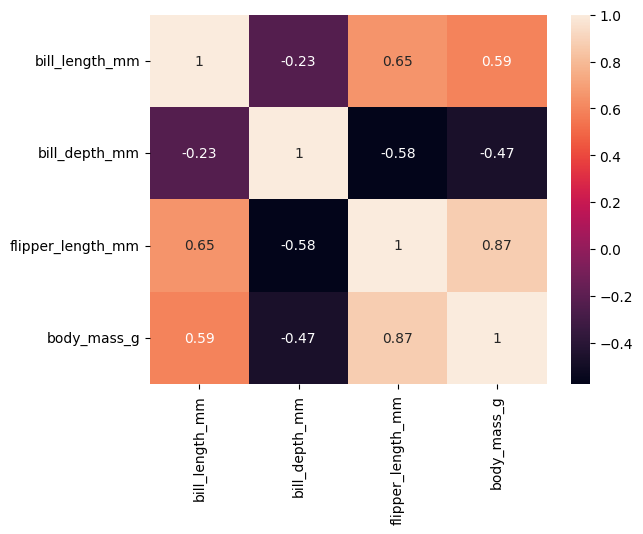

In [134]:
# computer correlations for the numeric data
correlations = penguin_numeric_only.corr()
_ = sns.heatmap(correlations, annot=True)

Take a look at the coefficients. You should see a strong relationship between the `body_mass_g` and `flipper_length_mm` variables (0.87). Flipper length and body mass are positively correlated. That makes intuitive sense, nice to see the data confirming our intuituions.

Make a scatterplot of the two values, `body_mass_g` and `flipper_length_mm`, to see how the relationship looks on a graph. `sns.scatterplot()` is one way to do this. You need to give it arguments `data=`, `x=`, and `y=`.

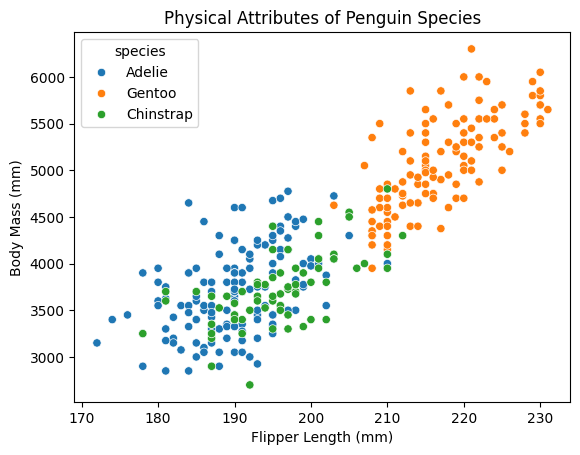

In [135]:
# generate a scatterplot below. sns.scatterplot() is one way to do this. You
# need to give arguments `data=`, `x=`, and `y=`

_ = sns.scatterplot(data=penguin_data, x='flipper_length_mm', y='body_mass_g', hue='species')
_ = plt.title('Physical Attributes of Penguin Species')
_ = plt.xlabel('Flipper Length (mm)')
_ = plt.ylabel('Body Mass (mm)')

You should see the data points on the graph. If you add `hue='species'`, you'll get a nicer plot that shows the species in different colors.

Here's another way to look at this relationship. `sns.lmplot()` (short for linear model plot) takes the same arguments: `data=`, `x=`, and `y=`. But what it adds by default is the best fit line through the data. Try it below.

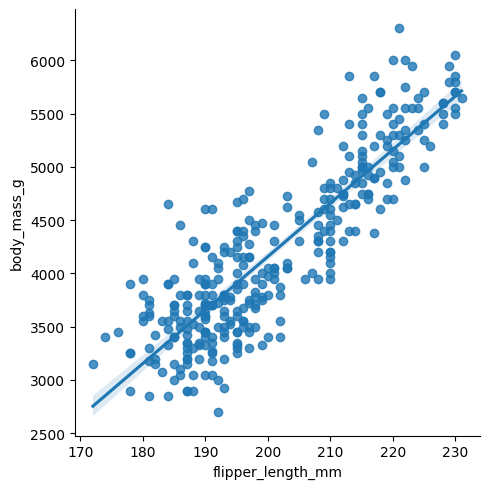

In [136]:
# use sns.lmplot() to see the data points and best-fit line
_ = sns.lmplot(data=penguin_data, x='flipper_length_mm', y='body_mass_g')            # fill in the arguments for the lmplot

You should see the line running through the data. We may be able to accurately predict body mass given flipper length. Before trying that, run `sns.lmplot()` again but include the argument `col=`. You can set that equal to a categorical variables (e.g., `species`) to see individual plots for each category. Try it below.

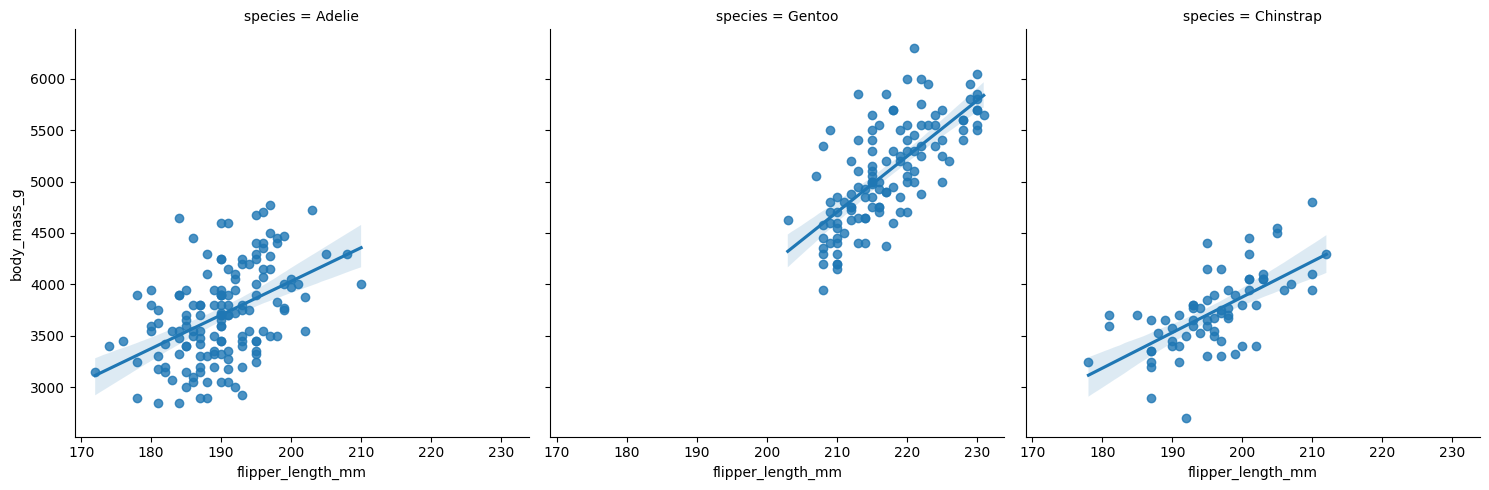

In [137]:
# use sns.lmplot with col='species'
sns.lmplot(data=penguin_data, x='flipper_length_mm', y='body_mass_g', col='species')            # fill in the arguments

## Question: What do you see in these visualizations?
In the cell below, tell us what you notice in these visualizations?

I see all three lines having very strong correlation, with especially gentoo having the highest correlation value between the two variables, with the tightest area for standard error.  While both adiele and chinstrap having smaller penguins overall, that have a bit more error and less correlation in their respective graphs.

## Linear Regression
Let's try building a model. First, we need to split our data into a training set and a test set. We'll need some libraries.

In [138]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn import preprocessing
import numpy as np

We'll make two variables, `flipper_length` and `body_mass`. Let's pull those columns from the original penguins_data.

In [139]:
# set flipper_length equal to the data in the flipper_length_mm column
flipper_length = pd.DataFrame(penguin_data['flipper_length_mm'])

# set body_mass equal to the data in the body_mass_g column
body_mass = pd.DataFrame(penguin_data['body_mass_g'])


Now we'll split the data into training and test sets. You saw this in the practice linear regression notebook: We need train_test_split. Give it a random_state of 16. And set the test_size to 0.3. That will make it use 30% of the data for testing.

In [140]:
# split the data into training and test sets. You fill in the arguments to train_test_split below
flipper_length_train, flipper_length_test, body_mass_train, body_mass_test = train_test_split(flipper_length, body_mass, test_size = 0.3, random_state = 16)

Making the model is simple. You'll see this basic structure a lot:
1. Initialize the `model`.
2. `fit` the model on the training data
3. call the `model`'s `predict` function on the test data.
4. compute the `model` `score` to see how well we did.

In [141]:
# making the linear regression model

# 1. initialize a LinearRegression model
model = LinearRegression()

# 2. fit the model on the training data
model.fit(flipper_length_train, body_mass_train)     # fill in training variables for the arguments

# 3. call predict with the flipper_length test data
body_mass_predictions = model.predict(flipper_length_test) # call model with argument here



Now that we've used our model to predict penguin body masses in our test dataset, let's see how well our predictions match the actual values!

One simple way to evaluate our model is to create a scatterplot comparing the actual body masses (x-axis) with our predicted body masses (y-axis). If our model made perfectly accurate predictions, every point would fall along a diagonal line where the predicted value equals the actual value.

We'll use Seaborn's `scatterplot()` function to create this graph, and add a dashed diagonal line to show where perfect predictions would fall.

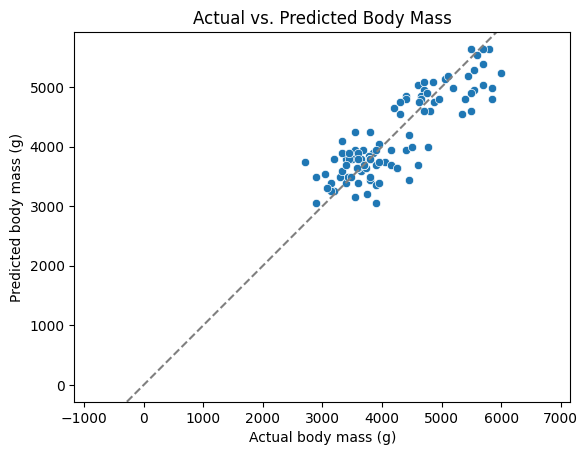

In [142]:
# Plot actual vs. predicted body masses
#sns.scatterplot(x=body_mass_test, y=body_mass_predictions)

sns.scatterplot(x=np.ravel(body_mass_test), y=np.ravel(body_mass_predictions))

# Add a reference line showing perfect predictions
plt.axline((0, 0), slope=1, color="gray", linestyle="--")
plt.axis("equal")

plt.xlabel("Actual body mass (g)")
plt.ylabel("Predicted body mass (g)")
plt.title("Actual vs. Predicted Body Mass")
plt.show()

That graph should look roughly linear but will almost never be perfectly linear.  

Wait, isn't this different from our earlier regression plots?

Yes! Earlier, when we were building our regression model, we plotted the relationship between our predictor variable (x) and our outcome variable (y). For example, we might have plotted penguin flipper length against body mass to see how the two variables were related.

This graph is doing something different! We're now plotting our actual outcome values (y) against our model's predicted outcome values (ŷ, or "y-hat"). Both axes represent body mass, measured in grams.

We're no longer trying to understand the relationship between two different variables. Instead, we're evaluating how closely our model's predictions match reality. That's why we've added a diagonal line representing perfect predictions, rather than fitting a new regression line through the points.

What we'll do next is compute the $R^2$ score. This tells us how well a model fits the data. A value of 0 means the target can't be predicted by the prediction variables at all. A value of 1 is a perfect fit. What we'll do next is to look at R-squared scores for the training data, test data, and the test + predictions. We'll do this to see how well the model predictions align with the fit of the original data.

In [143]:
from sklearn.metrics import mean_absolute_error, r2_score

r_squared_train = round(model.score(flipper_length_train, body_mass_train) * 100)
r_squared_test = round(model.score(flipper_length_test, body_mass_test) * 100)
r_squared_predictions = round(r2_score(body_mass_test, body_mass_predictions) * 100)
mae = round(mean_absolute_error(body_mass_test, body_mass_predictions))


print(f"Training Data R-squared: {r_squared_train}%")
print(f"Test Data R-squared: {r_squared_test}%")
print(f"The model's R-squared score: {r_squared_predictions}%")
print(f"Mean Absolute Error: {mae}g")

Training Data R-squared: 78%
Test Data R-squared: 73%
The model's R-squared score: 73%
Mean Absolute Error: 337g


The R-squared value for the training data is 78%. Our model that generated precictions comes in at 73%. So we're not far off...the original data is just at 78%. Maybe we can improve this with multiple predictor variables? Let's save that for later.

# Classification and Logistic Regression
Another thing we might want to do with this dataset is predict a penguin's species given its anatomical measurements. This would be a *classification* problem, as the target variable is categorical. That is, we'll use body measures to decide if a penguin belongs to the Adelie, Gentoo, or Chinstrap species.  

Before moving onto models, let's create some visuals to explore the data. We'll do this using another useful visualization function, `sns.pairplot()`.

The `year` column wont show us much here (although you're welcome to include it and see the results), so we're going to drop it when we make the pairplot. Then we'll call `sns.pairplot()` with the data minus the year.

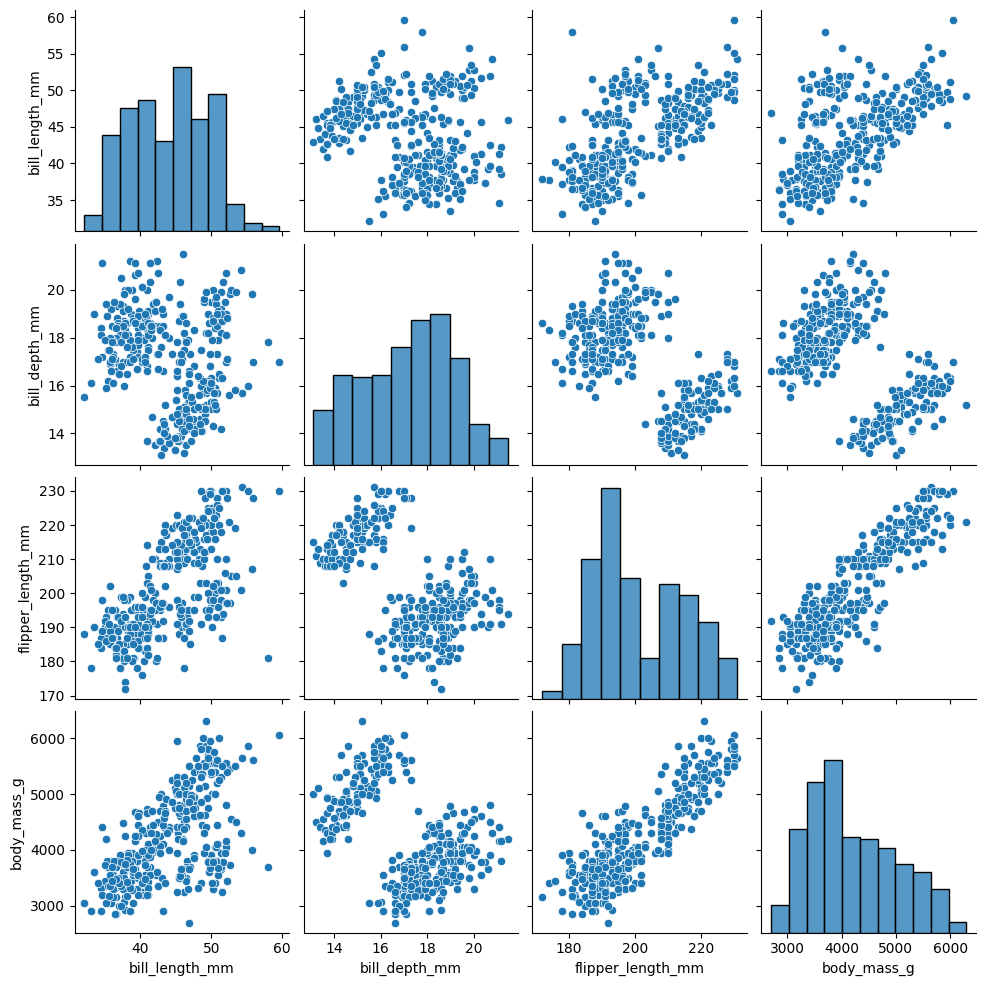

In [144]:
# drop the year for the pairplot
penguin_data_minus_year = penguin_data[['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex']] # ENTER THE DROP CODE HERE

# make the pairplot figure
pairplot_figure = sns.pairplot(data=penguin_data_minus_year)
_ = plt.show()

That's not as useful as promised. We'll do much better if we use the `hue=` argument in `pairplot()`. That will group the data and color values accordingly. We're going to use the `species` to group/color the plots.

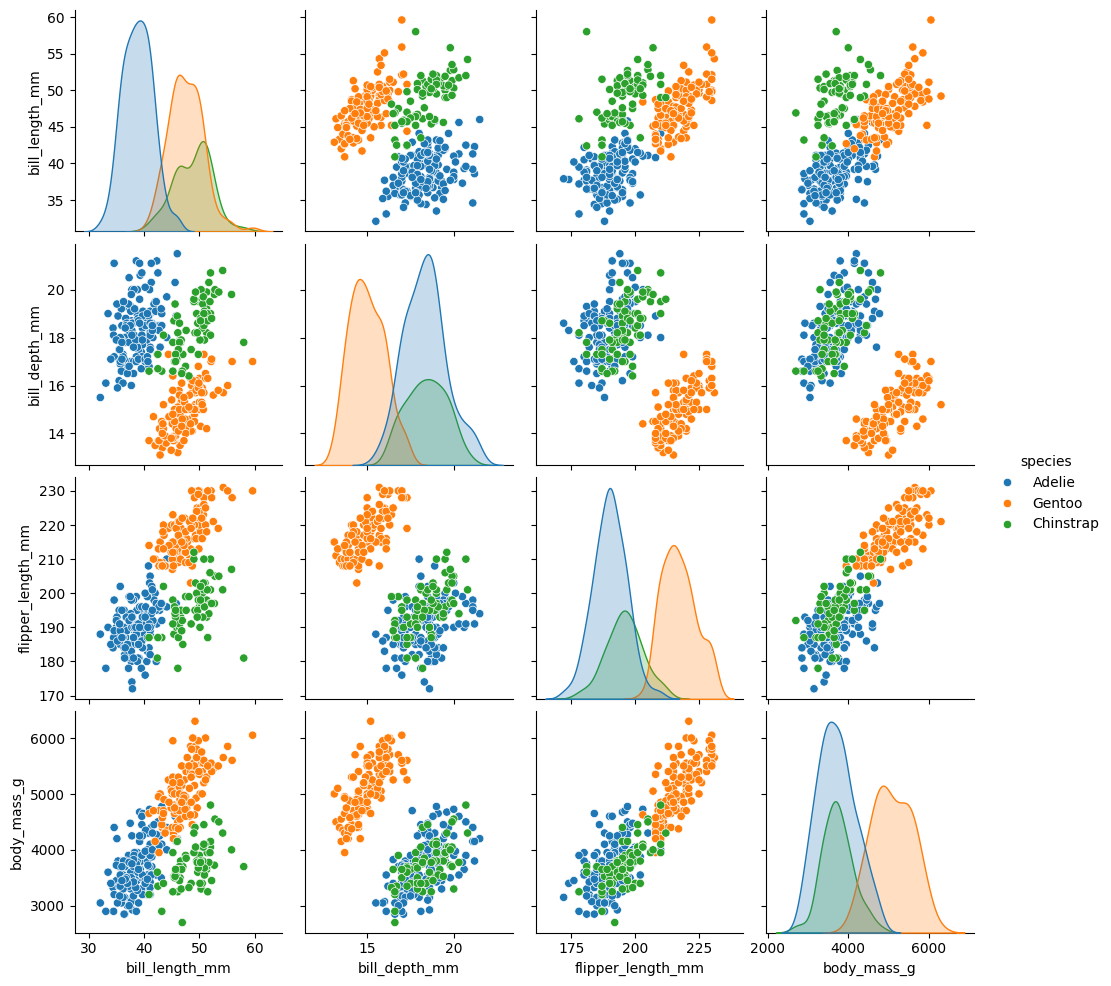

In [145]:
_ =  sns.pairplot(data=penguin_data_minus_year, hue='species')

Now *this* is interesting. Each plot shows the species data by pairs. You can use these plots to visually inspect the data and see which categories are more easily distinguished. We'll expand two of these to take a closer look. First, we'll inspect the relationship between `bill_depth_mm` and `body_mass_g`.

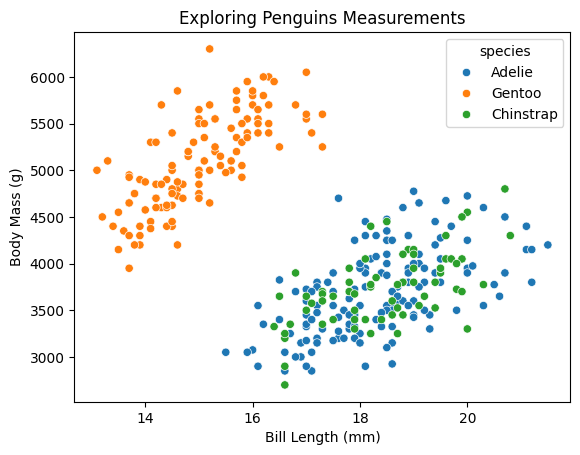

In [146]:
_= sns.scatterplot(data=penguin_data,
                   x='bill_depth_mm',
                   y='body_mass_g',
                   hue='species',       # color by species
                   palette="tab10"      # change the color palette
)

_ = plt.title('Exploring Penguins Measurements')
_ = plt.xlabel('Bill Length (mm)')
_ = plt.ylabel('Body Mass (g)')

What can you see from this? You should see that Gentoo is easily distinguishable by looking at `bill_depth` and `body_mass` alone. But Adelie and Chinstrap are close enough on these measures that we couldn't simply use them to determine a penguin's species.  

If you look back to the pairplot figure above, you'll see a more promising pair for classification. We'll look at the relationship between `bill_depth` and `bill_length`.

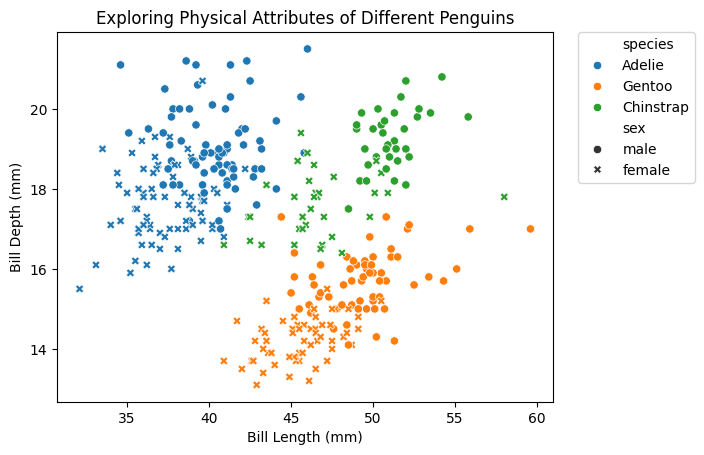

In [147]:
_ =sns.scatterplot(
    data=penguin_data,
    x='bill_length_mm',
    y='bill_depth_mm',
    hue='species',      # color by species
    style='sex',        # throwing in in the penguin's gender
    palette="tab10")    # change the color palette

_ = plt.title('Exploring Physical Attributes of Different Penguins')
_ = plt.xlabel('Bill Length (mm)')
_ = plt.ylabel('Bill Depth (mm)')

# change the location of the legend
_ = plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0)
_ = plt.show()

Here, the three species appear to be in well-defined clusters. So there's hope that we coukld build a model to categorize a new penguin's species.  

Let's build a model. Because we're classifying, we're going to use **logistic regression**.


In [160]:
# import some libraries.
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn import preprocessing

### Encoding categorical variables
Look at the head of penguin data.

In [161]:
# call head on penguin_data
penguin_data.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,0,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,0,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,0,Torgersen,40.3,18.0,195.0,3250.0,female,2007
4,0,Torgersen,36.7,19.3,193.0,3450.0,female,2007
5,0,Torgersen,39.3,20.6,190.0,3650.0,male,2007


The `species`, `island`, and `sex` are categorical variables that have descriptive names (e.g., "Adelie"). Machine learning models don't like names...they *love* numbers. We're going to convert those categories from strings into numbers.  

We could do this manually. For example, we could find every unique category and then assign it a number. Something like this:

In [162]:
# find unique species names and convert them into a list
unique_species = penguin_data['species'].unique().tolist()

# now convert these into numbers
unique_species_numbers = []

# loop over the species names. assign each a number that is it's index in the list
for i in range(0, len(unique_species)):
    unique_species_numbers.append(i)

print("Unique species names:", unique_species)
print("Unique species by number:", unique_species_numbers)


Unique species names: [0, 2, 1]
Unique species by number: [0, 1, 2]


That would work. Or we can use scikit-learn's `LabelEncoder` and `fit_transform()` function. Here's how to use it.

In [163]:
# create a LabelEncoder. This will do the translating from string to number
le = preprocessing.LabelEncoder()

# use fit_transform to change the string to a number
penguin_data['species'] = le.fit_transform(penguin_data['species'])
penguin_data['island'] = le.fit_transform(penguin_data['island'])
penguin_data['sex'] = le.fit_transform(penguin_data['sex'])

We look at the head to see that the species values are now numbers. You make the calls to `fit_transform()` below to encode `island` and `sex` as numbers.

In [164]:
# call fit_transform on the island and sex columns below

# let's make sure those columns are now numerical
penguin_data.head()


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,0,2,39.1,18.7,181.0,3750.0,1,2007
1,0,2,39.5,17.4,186.0,3800.0,0,2007
2,0,2,40.3,18.0,195.0,3250.0,0,2007
4,0,2,36.7,19.3,193.0,3450.0,0,2007
5,0,2,39.3,20.6,190.0,3650.0,1,2007


Great! You should have numbers in those three columns. Now we'll split the data into two parts: The data to classify with and the outcome category. We'll end up with a variable `X` that contains the majority of the data: These are the predictors. And we'll have a variable `y` that contains the categories we want to predict from each row. That category is our `species` column.

In [165]:
# Set X to the penguin dataset. BUT drop the species column. And you'll need to specify
# axis='columns' in the drop(). That tells pandas to drop a column vs. a row.

X =  penguin_data.drop(['species'], axis='columns') # FILL IN DROP ARGUMENTS

# now set y to the species column
y = penguin_data['species'] # GET SPECIES COLUMN HERE

### Split the data into training and test sets
We can use `train_test_split` to divide X and y into training and test sets. Remember that we'll train our model with training data. We hold the test data aside to evaluate the model's performance. You've seen how `train_test_split` works. Call it below with the existing variables (e.g., penguin_train). Make the test_size=0.3 and the random_state=16.

In [166]:
# call train_test_split() below with with X, y, test_size=0.3, and random_state=16
# fill in the arguments
penguin_train, penguin_test, species_train, species_test = train_test_split(X, y, test_size=0.3, random_state=16)

We'll check the shapes of each chunk of data.

In [167]:
print("penguin_train:", penguin_train.shape)
print("penguin_test:", penguin_test.shape)
print("species_train:", species_train.shape)
print("species_test:", species_test.shape)

penguin_train: (233, 7)
penguin_test: (100, 7)
species_train: (233,)
species_test: (100,)


You can see that the training and test data both have 7 columns. The training data has 233 rows, and we left 100 rows behind for testing. The species data only have one column which is why you only see (233,) and no column number afterwards.  

Now it's time to make the model. Once again, we follow this structure:
1. Initialize the `model`.
2. `fit` the model on the training data
3. call the `model`'s `predict` function on the test data.
4. compute the `model` `score` to see how well we did.

Start by initializing a `LogisticRegression()` model. Give it a random_state of 16 so we can duplicate our results. You should also include an argument called `max_iter=`. This increases the number of iterations the model makes trying to fit the data. It might give you a warning/error if the model doesn't find a convergence point. By increasing the iterations, you're more likely to find that point. So set `max_iter=4000` for now.

In [168]:
# create an empty Logisitic Regression model with random_state = 16, max_iter=4000
LR = LogisticRegression(random_state=16, max_iter=4000) # FILL IN CODE HERE

`LR` is our empty logistic regression model. Now train it using `fit()` and the training data. And then use `predict()` with the penguin test data to generate predictions.

In [169]:
# use the training data to "fit" the model on the *training* data.
LR.fit(penguin_train, species_train)    # FILL IN ARGUMENTS

# assign the results of predict() to species_predictions. You'll call predict()
# with the penguin test data
species_predictions = LR.predict(penguin_test) # FILL IN PREDICT CALL


Now we have a set of predictions. We'll look at those in a minute. But we'll do something that should look odd at first glance. We're going to use `score()` to see how well our model does at classifying with known data. This should be a pretty high number. If not, we know something is wrong with the model: The actual data should correctly predict the penguin species.

In [170]:
# score the test data. this ought to be near perfect...
LR.score(penguin_test, species_test)

0.99

Can't argue with 0.99. But remember this is scoring the "ground truth". We expect this to be as close to accurate as 99%. Now we want to see how well the model did with generating predictions.

First, let's see the "ground truth." `species_test` contains the categories we want to predict. Take a look at those using `value_counts()`.

In [171]:
# use value_counts() or any other method to see how many penguins are in species.
species_test.value_counts()

,count
species,
0,45
2,35
1,20


We're hoping that our predictions will be close to those true numbers. Let's take a look. But first, let's see what the model returns as `species_predictions`.

In [172]:
print("species_predictions is of type:", type(species_predictions))

species_predictions is of type: <class 'numpy.ndarray'>


`species_predictions` is a numpy ndarray. We can't work with that in the same way that we did with `species_test`. But we can convert the ndarray with `pd.DataFrame()` and then call `value_counts()` to see the totals. Try it.

In [173]:
# set species_predictions_df to a new dataframe built with species_predictions
species_predictions_df = pd.DataFrame(species_predictions)# make a dataframe with series_predictions

# now compute the value_counts() for species_predictions_df
species_predictions_df.value_counts()

,count
0,
0,44
2,35
1,21


Those numbers look...well, there are only a couple of missed predictions! Let's make a confusion matrix to get a better sense of this. scikit-learn has a function called `confusion_matrix()`. Pass it the species test data and the species predictions.

In [177]:
# import confusion_matrix from scikit-learn's metrics module
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# call confusion matrix using species test data and the predictions
penguin_confusion_matrix = confusion_matrix(species_test, species_predictions) # Call confusion_matrix() with  species_test and species_predictions

# show it
display(penguin_confusion_matrix)

array([[44,  1,  0],
       [ 0, 20,  0],
       [ 0,  0, 35]])

That contains the values. Let's make it easier to read using scikit-learn's `ConfusionMatrixDisplay()`.

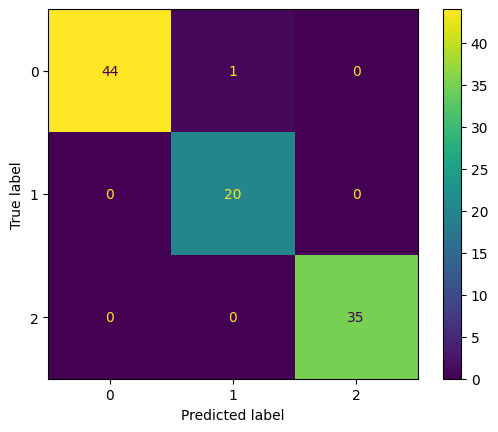

In [178]:
_ = cmplot = ConfusionMatrixDisplay(penguin_confusion_matrix)
_ = cmplot.plot()

Before we look at this, let's do some more work to make the visualization more readable.

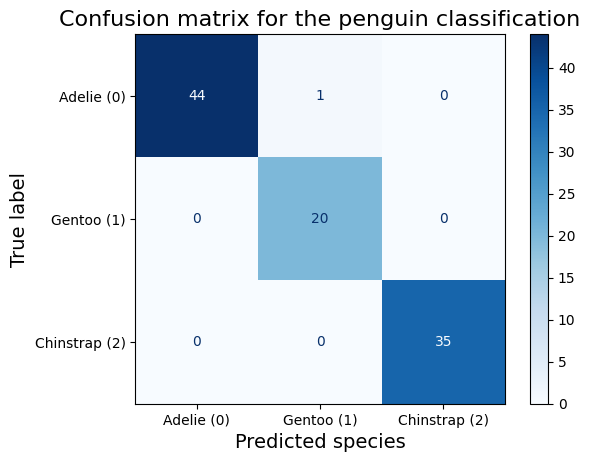

In [179]:
# bring back the species names
species_names = ['Adelie (0)', 'Gentoo (1)', 'Chinstrap (2)']
_ = cmplot = ConfusionMatrixDisplay(penguin_confusion_matrix,
                                    display_labels=species_names)   # we'll display the species names

# changing the color map to blues
_ = cmplot.plot(cmap=plt.get_cmap('Blues'))

# make some titles
_ = plt.title("Confusion matrix for the penguin classification", fontsize=16)
_ = plt.xlabel("Predicted species", fontsize=14)
_ = plt.ylabel("True label", fontsize=14)

_ = plt.show()


Finally, it's good practice to print a classification report to look at precision, recall, etc.

In [180]:
from sklearn.metrics import classification_report

print(classification_report(species_test, species_predictions))

              precision    recall  f1-score   support

           0       1.00      0.98      0.99        45
           1       0.95      1.00      0.98        20
           2       1.00      1.00      1.00        35

    accuracy                           0.99       100
   macro avg       0.98      0.99      0.99       100
weighted avg       0.99      0.99      0.99       100



You can see we have strong performance with the logistic regression model. You saw how to interpret this report in an earlier notebook. Take a look at that one and see how you'd interpret these values.

We'll do more modeling next week. If you're curious, you can try doing a few things with the penguins.
1. We did linear regression with a single variable. What happens if you train a model using two or more measurements to predict another? For example, what happens if you use `bill_length_mm` and `bill_depth_mm` to predict `body_mass_g`?
2. We classified by species. What if we have body measurements for a penguin, we don't know the species, but we want to predict what island it came from? How would you build a classifier that predicts "island"?
There's always more data visualizations to be generated.

Finally, you can learn more about the penguins [here](https://apreshill.github.io/palmerpenguins-useR-2022/#/title-slide).